[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch06_metrics.ipynb)

# 6장 모델을 어떻게 평가하는가 — 분류 평가 지표 · 실습 노트북
『딥러닝 응용 — 보고, 읽고, 설명하는 딥러닝』

6장 본문에 나오는 코드를 순서대로 실행해 봅니다. 위에서부터 차례로 실행하세요.
- 3장의 Fashion-MNIST CNN을 다시 학습하고, 테스트 데이터로 평가합니다.
- 6.2 혼동 행렬: 어떤 옷끼리 헷갈리는가
- 6.3~6.5 "셔츠인가 아닌가" 문제로 정밀도·재현율·임계값·F1
- 6.6 PR 곡선과 AP
- 6.7 다중 클래스 평균과 `classification_report`
- 6.8 학습 데이터로 평가하면 생기는 일
- 실습: 양성 범주 바꾸기, 재현율 목표에 맞는 임계값 찾기, 불균형 테스트 세트에서 평균 비교

> CPU로도 실행할 수 있지만(학습 약 3~5분), 메뉴 [런타임] → [런타임 유형 변경]에서 **T4 GPU**를 고르면 더 빠릅니다.

## 준비

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_curve, average_precision_score,
                             roc_auc_score, classification_report)

tf.keras.utils.set_random_seed(42)   # 실행할 때마다 결과가 크게 달라지지 않도록
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 3장의 Fashion-MNIST CNN 다시 학습하기
3장 3.9절과 같은 데이터, 같은 모델, 같은 학습 설정(5에포크)입니다.

In [2]:
(x_train, y_train), (x_test, y_test) = \
    tf.keras.datasets.fashion_mnist.load_data()

X_train_final = x_train.reshape((-1, 28, 28, 1)) / 255.
X_test_final = x_test.reshape((-1, 28, 28, 1)) / 255.

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
model_with_conv = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu',
                           input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2), strides=2),
    tf.keras.layers.Conv2D(64, (3, 3), padding='same',
                           activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2), strides=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_with_conv.compile(optimizer='adam',
                        loss='sparse_categorical_crossentropy',
                        metrics=['accuracy'])
model_with_conv.fit(X_train_final, y_train, epochs=5)
model_with_conv.evaluate(X_test_final, y_test, verbose=2)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.8589 - loss: 0.3931
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9054 - loss: 0.2582
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9204 - loss: 0.2128
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9349 - loss: 0.1765
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9456 - loss: 0.1463
313/313 - 3s - 10ms/step - accuracy: 0.9097 - loss: 0.2808


[0.2807987928390503, 0.9096999764442444]

테스트 사진 10,000장 각각에 대해 10개 범주의 확률을 구하고, 가장 큰 확률의 범주를 예측으로 삼습니다.

In [4]:
probs = model_with_conv.predict(X_test_final, verbose=0)   # (10000, 10)
y_pred = np.argmax(probs, axis=1)
print("정확도:", accuracy_score(y_test, y_pred))

정확도: 0.9097


## 6.2 혼동 행렬
행은 실제 범주, 열은 예측한 범주입니다. 대각선은 맞힌 개수, 나머지는 틀린 개수입니다.

In [5]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[800   1  30  29   5   1 127   0   6   1]
 [  0 989   0   7   1   0   2   0   1   0]
 [ 13   1 878  10  59   0  39   0   0   0]
 [  6   2  11 941  21   0  19   0   0   0]
 [  0   0  59  20 894   0  27   0   0   0]
 [  1   0   0   0   0 953   0  41   0   5]
 [ 62   0  68  37  99   0 729   0   5   0]
 [  0   0   0   0   0   0   0 995   0   5]
 [  3   0   3   7   2   1   5   2 977   0]
 [  0   0   0   0   0   3   1  55   0 941]]


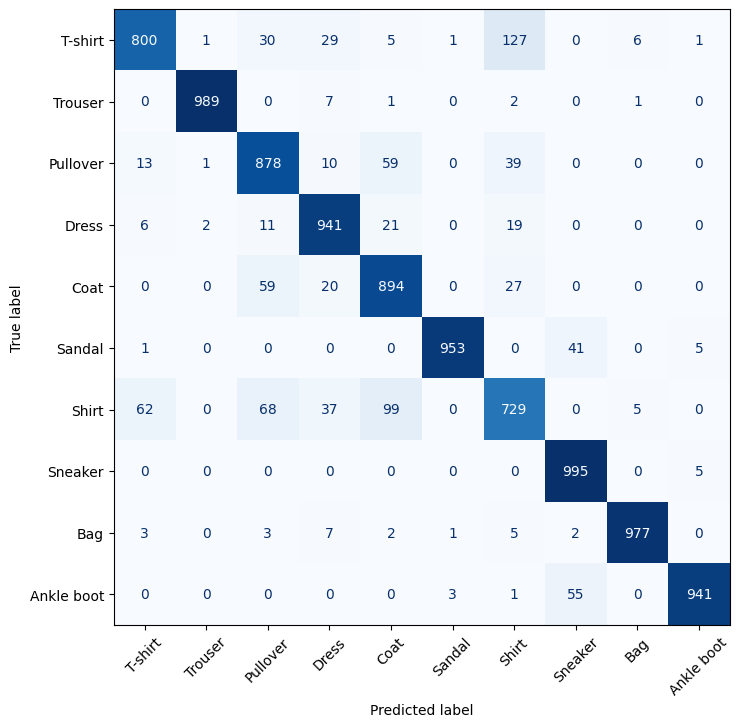

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues',
                                                             xticks_rotation=45, colorbar=False)
plt.show()

어떤 범주끼리 가장 많이 헷갈렸는지 대각선 밖에서 큰 값부터 찾아봅니다.

In [7]:
off = cm.copy()
np.fill_diagonal(off, 0)
for idx in np.argsort(off, axis=None)[::-1][:5]:
    i, j = np.unravel_index(idx, off.shape)
    print(f"실제 {class_names[i]:>10} → 예측 {class_names[j]:<10} {off[i, j]}장")

실제    T-shirt → 예측 Shirt      127장
실제      Shirt → 예측 Coat       99장
실제      Shirt → 예측 Pullover   68장
실제      Shirt → 예측 T-shirt    62장
실제       Coat → 예측 Pullover   59장


셔츠를 티셔츠로 잘못 예측한 사진 몇 장을 봅니다.

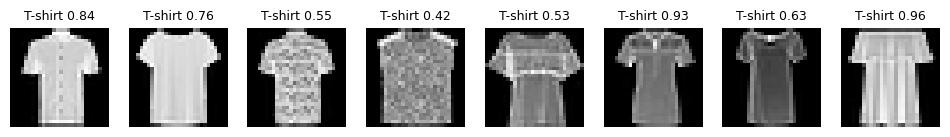

In [8]:
wrong = np.where((y_test == 6) & (y_pred == 0))[0][:8]
plt.figure(figsize=(12, 2))
for k, i in enumerate(wrong):
    plt.subplot(1, 8, k + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"T-shirt {probs[i, 0]:.2f}", fontsize=9)
    plt.axis('off')
plt.show()

## 6.1·6.3 "셔츠인가 아닌가" — 치우친 이진 분류
셔츠(6번)를 양성(positive), 나머지 9개 범주를 음성(negative)으로 봅니다. 테스트 데이터 10,000장 중 셔츠는 1,000장(10%)입니다.

먼저 모든 사진을 "셔츠 아님"이라고 답하는 모델의 정확도부터 봅시다.

In [9]:
y_true_bin = (y_test == 6).astype(int)      # 셔츠면 1, 아니면 0
print("셔츠 개수:", y_true_bin.sum(), "/", len(y_true_bin))

all_negative = np.zeros_like(y_true_bin)      # 전부 '셔츠 아님'
print("정확도:", accuracy_score(y_true_bin, all_negative))
print("재현율:", recall_score(y_true_bin, all_negative))

셔츠 개수: 1000 / 10000
정확도: 0.9
재현율: 0.0


이제 CNN이 낸 셔츠 확률을 점수로 씁니다. 점수가 임계값 0.5 이상이면 "셔츠"로 예측합니다.

In [10]:
score = probs[:, 6]                          # 셔츠일 확률
y_pred_bin = (score >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin).ravel()
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print("정확도:", accuracy_score(y_true_bin, y_pred_bin))
print("정밀도:", precision_score(y_true_bin, y_pred_bin))
print("재현율:", recall_score(y_true_bin, y_pred_bin))
print("F1    :", f1_score(y_true_bin, y_pred_bin))

TP=702  FP=190  FN=298  TN=8810
정확도: 0.9512
정밀도: 0.7869955156950673
재현율: 0.702
F1    : 0.7420718816067653


정밀도와 재현율을 공식대로 직접 계산해도 같은 값이 나옵니다.

In [11]:
print("정밀도 = TP / (TP + FP) =", tp / (tp + fp))
print("재현율 = TP / (TP + FN) =", tp / (tp + fn))
p, r = tp / (tp + fp), tp / (tp + fn)
print("F1 = 2PR / (P + R)      =", 2 * p * r / (p + r))

정밀도 = TP / (TP + FP) = 0.7869955156950673
재현율 = TP / (TP + FN) = 0.702
F1 = 2PR / (P + R)      = 0.7420718816067654


## 6.4 임계값을 바꾸면
임계값을 낮추면 "셔츠"라고 답하는 사진이 늘어나고, 높이면 줄어듭니다.

In [12]:
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred = (score >= t).astype(int)
    print(f"임계값 {t:.1f}: 셔츠로 예측 {pred.sum():5d}장  "
          f"정밀도 {precision_score(y_true_bin, pred):.3f}  "
          f"재현율 {recall_score(y_true_bin, pred):.3f}  "
          f"F1 {f1_score(y_true_bin, pred):.3f}")

임계값 0.1: 셔츠로 예측  1512장  정밀도 0.587  재현율 0.888  F1 0.707
임계값 0.3: 셔츠로 예측  1112장  정밀도 0.714  재현율 0.794  F1 0.752
임계값 0.5: 셔츠로 예측   892장  정밀도 0.787  재현율 0.702  F1 0.742
임계값 0.7: 셔츠로 예측   708장  정밀도 0.855  재현율 0.605  F1 0.708
임계값 0.9: 셔츠로 예측   451장  정밀도 0.942  재현율 0.425  F1 0.586


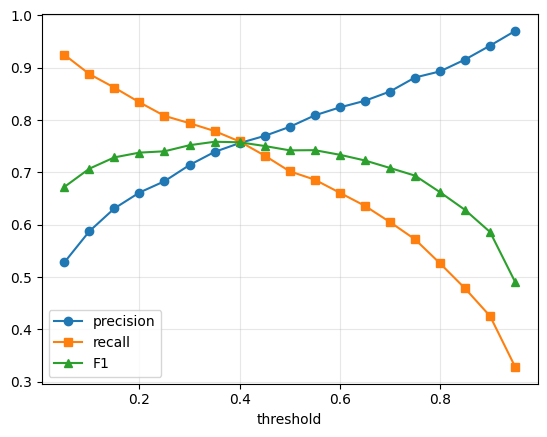

In [13]:
ts = np.linspace(0.05, 0.95, 19)
P = [precision_score(y_true_bin, (score >= t).astype(int)) for t in ts]
R = [recall_score(y_true_bin, (score >= t).astype(int)) for t in ts]
F = [f1_score(y_true_bin, (score >= t).astype(int)) for t in ts]
plt.plot(ts, P, 'o-', label='precision')
plt.plot(ts, R, 's-', label='recall')
plt.plot(ts, F, '^-', label='F1')
plt.xlabel('threshold'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 6.5 F1은 낮은 쪽에 끌려간다
정밀도 0.9, 재현율 0.1이면 산술평균은 0.5지만 F1(조화평균)은 0.18입니다.

In [14]:
p, r = 0.9, 0.1
print("산술평균:", (p + r) / 2)
print("F1      :", 2 * p * r / (p + r))

산술평균: 0.5
F1      : 0.18000000000000002


## 6.6 PR 곡선과 AP
`precision_recall_curve`는 가능한 모든 임계값에서 정밀도와 재현율을 계산해 줍니다. 곡선 아래 넓이를 요약한 값이 AP(average precision)입니다.

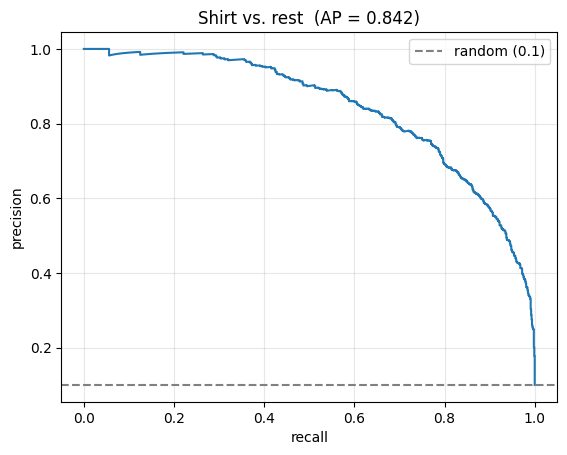

AP: 0.8421036484372265


In [15]:
precision, recall, thresholds = precision_recall_curve(y_true_bin, score)
ap = average_precision_score(y_true_bin, score)

plt.plot(recall, precision)
plt.xlabel('recall'); plt.ylabel('precision')
plt.title(f'Shirt vs. rest  (AP = {ap:.3f})')
plt.axhline(y_true_bin.mean(), ls='--', c='gray', label='random (0.1)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()
print("AP:", ap)

비교를 위해 ROC-AUC도 계산해 봅니다. 음성이 훨씬 많은 문제에서는 ROC-AUC가 AP보다 훨씬 높게 나오는 경향이 있습니다.

In [16]:
print("ROC-AUC:", roc_auc_score(y_true_bin, score))

ROC-AUC: 0.9744607777777778


## 6.7 다중 클래스: classification_report
범주마다 정밀도·재현율·F1과 함께, 두 가지 평균(macro, weighted)과 정확도를 보여 줍니다. 다중 클래스에서는 micro 평균 대신 정확도(accuracy) 줄이 나오는데, 둘은 같은 값입니다.

In [17]:
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

     T-shirt      0.904     0.800     0.849      1000
     Trouser      0.996     0.989     0.992      1000
    Pullover      0.837     0.878     0.857      1000
       Dress      0.895     0.941     0.918      1000
        Coat      0.827     0.894     0.859      1000
      Sandal      0.995     0.953     0.973      1000
       Shirt      0.768     0.729     0.748      1000
     Sneaker      0.910     0.995     0.951      1000
         Bag      0.988     0.977     0.982      1000
  Ankle boot      0.988     0.941     0.964      1000

    accuracy                          0.910     10000
   macro avg      0.911     0.910     0.909     10000
weighted avg      0.911     0.910     0.909     10000



In [18]:
for avg in ['macro', 'micro', 'weighted']:
    print(f"{avg:>8} F1: {f1_score(y_test, y_pred, average=avg):.3f}")

   macro F1: 0.909
   micro F1: 0.910
weighted F1: 0.909


## 6.8 학습 데이터로 평가하면
모델이 이미 본 학습 데이터로 평가하면 성능이 실제보다 좋게 나옵니다.

In [19]:
_, train_acc = model_with_conv.evaluate(X_train_final, y_train, verbose=0)
_, test_acc = model_with_conv.evaluate(X_test_final, y_test, verbose=0)
print(f"학습 데이터 정확도: {train_acc:.4f}")
print(f"테스트 데이터 정확도: {test_acc:.4f}")

학습 데이터 정확도: 0.9462
테스트 데이터 정확도: 0.9097


## 실습
1. **양성 범주 바꾸기**: 셔츠(6) 대신 스웨터(2), 샌들(5)을 양성으로 바꿔 PR 곡선을 그리고 AP를 비교해 보세요. 어느 범주가 가장 어렵나요? 혼동 행렬과 연결해 설명해 보세요.
2. **재현율 목표에 맞는 임계값**: 셔츠를 90% 이상 찾아내야 한다면(재현율 ≥ 0.9) 임계값을 얼마로 해야 할까요? 그 조건을 만족하는 가장 높은 임계값과 그때의 정밀도를 구해 보세요.
3. **불균형 테스트 세트**: 테스트 데이터에서 셔츠를 100장만 남기고 나머지 셔츠 900장을 빼 보세요. 이 데이터로 `classification_report`를 다시 출력하고, macro 평균과 weighted 평균이 어떻게 달라지는지, 그 이유는 무엇인지 설명해 보세요.

먼저 직접 작성해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [20]:
# 직접 작성해 보세요


### 예시 답안

   Shirt: AP = 0.842
Pullover: AP = 0.933
  Sandal: AP = 0.996


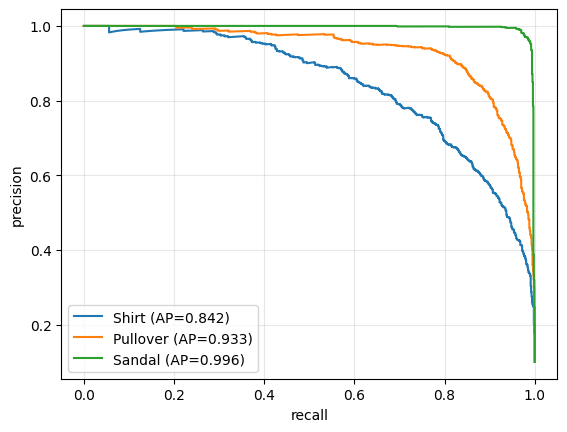

In [21]:
# 1. 양성 범주 바꾸기
for c in [6, 2, 5]:
    yt = (y_test == c).astype(int)
    pr, rc, _ = precision_recall_curve(yt, probs[:, c])
    ap_c = average_precision_score(yt, probs[:, c])
    plt.plot(rc, pr, label=f'{class_names[c]} (AP={ap_c:.3f})')
    print(f"{class_names[c]:>8}: AP = {ap_c:.3f}")
plt.xlabel('recall'); plt.ylabel('precision'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [22]:
# 2. 재현율 0.9 이상을 만족하는 가장 높은 임계값
ok = recall[:-1] >= 0.9     # recall[i] ↔ thresholds[i]
i = np.where(ok)[0][-1]     # 오름차순 → 마지막 위치
print(f"임계값 {thresholds[i]:.3f}: 정밀도 {precision[i]:.3f}, 재현율 {recall[i]:.3f}")
pred = (score >= thresholds[i]).astype(int)
print("셔츠로 예측한 사진:", pred.sum(), "장")

임계값 0.085: 정밀도 0.575, 재현율 0.900
셔츠로 예측한 사진: 1566 장


In [23]:
# 3. 셔츠를 100장만 남긴 불균형 테스트 세트
rng = np.random.default_rng(0)
shirt_idx = np.where(y_test == 6)[0]
drop = rng.choice(shirt_idx, size=900, replace=False)
keep = np.setdiff1d(np.arange(len(y_test)), drop)

print(classification_report(y_test[keep], y_pred[keep], target_names=class_names, digits=3))

              precision    recall  f1-score   support

     T-shirt      0.970     0.800     0.877      1000
     Trouser      0.996     0.989     0.992      1000
    Pullover      0.888     0.878     0.883      1000
       Dress      0.926     0.941     0.934      1000
        Coat      0.897     0.894     0.895      1000
      Sandal      0.995     0.953     0.973      1000
       Shirt      0.249     0.730     0.372       100
     Sneaker      0.910     0.995     0.951      1000
         Bag      0.993     0.977     0.985      1000
  Ankle boot      0.988     0.941     0.964      1000

    accuracy                          0.928      9100
   macro avg      0.881     0.910     0.883      9100
weighted avg      0.944     0.928     0.933      9100

